In [ ]:
!pip install pandas openpyxl scikit-learn matplotlib

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/GBM_GSM_Project/gsm_gbm_12features.xlsx"

df = pd.read_excel(file_path)

print(df.shape)
print(df["Y"].value_counts())

(183, 13)
Y
0    100
1     83
Name: count, dtype: int64


In [ ]:
print("Number of patients:", len(df))
print("Number of columns:", df.shape[1])

print("\nClass distribution:")
print(df["Y"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Number of patients: 183
Number of columns: 13

Class distribution:
Y
0    100
1     83
Name: count, dtype: int64

Missing values:
original_shape_MajorAxis                           0
original_shape_Sphericity                          0
original_glcm_JointEntropy                         0
original_glcm_MaximumProbability                   0
log-sigma-3-0-mm-3D_glszm_SizeZoneNonUniformity    0
log-sigma-5-0-mm-3D_firstorder_RootMeanSquared     0
wavelet-LLL_firstorder_Kurtosis                    0
wavelet-LHH_firstorder_Variance                    0
wavelet-HHL_firstorder_Skewness                    0
wavelet-HHL_gldm_LowGrayLevelEmphasis              0
squareroot_glrlm_HighGrayLevelRunEmphasis          0
squareroot_glrlm_RunVariance                       0
Y                                                  0
dtype: int64

Duplicate rows:
0


In [ ]:
#Separation de X et Y

X = df.drop(columns=["Y"])
y = df["Y"]

print("X:", X.shape)
print("y:", y.shape)

print("\nFeatures:")
for feature in X.columns:
    print(feature)


X: (183, 12)
y: (183,)

Features:
original_shape_MajorAxis
original_shape_Sphericity
original_glcm_JointEntropy
original_glcm_MaximumProbability
log-sigma-3-0-mm-3D_glszm_SizeZoneNonUniformity
log-sigma-5-0-mm-3D_firstorder_RootMeanSquared
wavelet-LLL_firstorder_Kurtosis
wavelet-LHH_firstorder_Variance
wavelet-HHL_firstorder_Skewness
wavelet-HHL_gldm_LowGrayLevelEmphasis
squareroot_glrlm_HighGrayLevelRunEmphasis
squareroot_glrlm_RunVariance


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("training:", X_train.shape)
print("testing:", X_test.shape)

print("\nTraining classes before SMOTE:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())



training: (146, 12)
testing: (37, 12)

Training classes before SMOTE:
Y
0    80
1    66
Name: count, dtype: int64

Testing classes:
Y
0    20
1    17
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train) #calcule la moyenne et l ecart type de chaque variable uniquement les patients de train
# tranform signifie utilisé ces moyennes et écarts-types pour transformer les valeurs

#On utilise pas fit dans le test pour eviter une fuite de données
X_test_scaled = scaler.transform(X_test)


#pour verifier que la standardisation n'a pas changé le nombre de patinets ni le nombre de variables
print("Train:", X_train_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (146, 12)
Test: (37, 12)


In [ ]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

svm.fit(X_train_scaled, y_train)
print("SVM training completed")

SVM training completed


In [ ]:
# le Test du svm
y_pred = svm.predict(X_test_scaled)

print("Real labels:")
print(y_test.to_numpy())

print("\nPredicted labels:")
print(y_pred)


Real labels:
[0 1 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 1 1 1 0 0 0 0 1 0 1 1 1 0 1 0 0]

Predicted labels:
[0 0 1 0 0 1 0 0 0 1 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 1 0 1 1 0 0 1 0 0]


In [ ]:
from sklearn.metrics import confusion_matrix

#Matrix de confusion pour voir ou le svm a raison et ou il se trompe
cm= confusion_matrix(y_test, y_pred)

print(cm)

#19 : vrais GBM correctement classés GBM
#1 : GBM incorrectement classés GSM
#5 : GSM incorrectement classés GBM
#12 : vrais GSM correctement classés GSM


[[19  1]
 [ 5 12]]


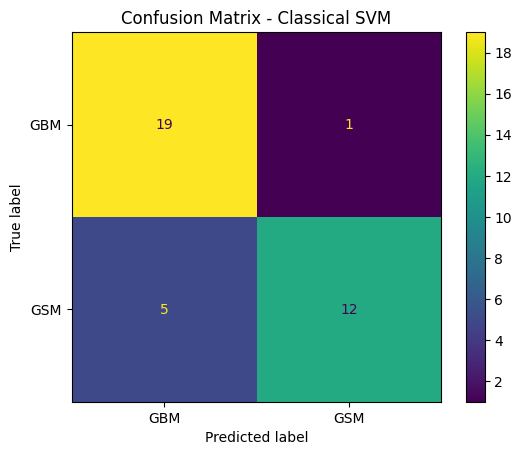

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["GBM", "GSM"]
)

plt.title("Confusion Matrix - Classical SVM")
plt.show()

#19 : vrais GBM correctement classés GBM
#1 : GBM incorrectement classés GSM
#5 : GSM incorrectement classés GBM
#12 : vrais GSM correctement classés GSM


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score
)

#on prend uniquement la probabilité estimée de GSM pour chacun des 37 patients
y_prob = svm.predict_proba(X_test_scaled)[:,1] 

#Proportion totale de patients correctement classifiés
accuracy = accuracy_score(y_test, y_pred)

#Parmi tous les vrais GSM, proportion correctement détéctée 12/17
recall = recall_score(y_test, y_pred) #sensitivity

#La capacité globale du modèle à distinguer GBM de GSM
auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy: {accuracy:.3f}")
print(f"Recall:   {recall:.3f}")
print(f"ROC-AUC:  {auc:.3f}")

Accuracy: 0.838
Recall:   0.706
ROC-AUC:  0.932


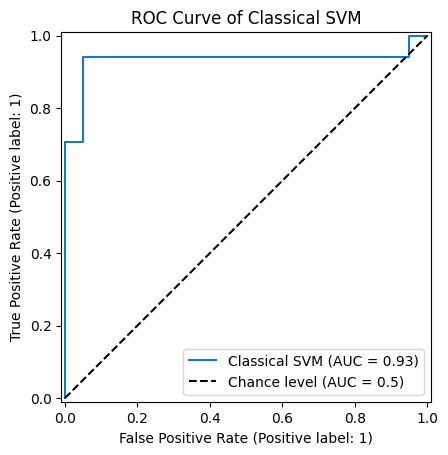

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Classical SVM",
    pos_label=1,
    plot_chance_level=True
)

plt.title("ROC Curve of Classical SVM")
plt.show()

#Y: combien de GSM détectés, parmi les vrais GSM
#X: parmi les vrais GBM, combien sont incorrectement classés GSM



La courbe ROC évalue la capacité du SVM à distinguer les patients GBM des patients GSM pour différents seuils de classification. Plus la courbe est proche du coin supérieur gauche, meilleure est la discrimination. Dans notre cas, nous obtenons une AUC de 0,93, ce qui indique une très bonne capacité du modèle à différencier les deux classes sur le jeu de test.

Accuracy
  : Avec une décision finale, combien sont corrects ?

ROC-AUC
  : Indépendamment d'un seul seuil, à quel point
  les scores du modèle séparent-ils GBM et GSM ?

In [ ]:
!pip install -q imbalanced-learn 

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline


# le but içi est de vérifier si mon SVM reste performant sur plusieurs sous-ensembles différents de X_train
# Tout en équilibrant la classe minoritaire GSM à chaque entrainement


# PIPELINE : StandardScaler → SMOTE → SVM

# Pour chaque fold :
# 1. StandardScaler apprend uniquement sur les patients
#    utilisés pour l'entraînement du fold.
#
# 2. SMOTE est appliqué uniquement sur cette partie TRAIN.
#    Il génère des observations GSM synthétiques afin
#    d'équilibrer les classes dans chaque fold d'entrainement.
#
# 3. Le SVM est ensuite entraîné sur les données équilibrées.
#
# Le fold de validation(test) n'est jamais modifié par SMOTE.

cv_svm = Pipeline([
    ("scaler", StandardScaler()),

    ("smote", SMOTE(
        random_state=42
    )),

    ("svm", SVC(
        kernel="rbf",
        C=1.0, #niveau de tolerance aux erreurs
        gamma="scale"#le rayon d influence de chaque point de donnée sur la frontière de decision
        # gamma contrôle la zone d'influence de chaque patient :
        # gamma faible = influence plus large
        # gamma élevé = influence plus locale
    ))
])


# VALIDATION CROISÉE STRATIFIÉE À 5 FOLDS

# Chaque fold conserve approximativement
# la même proportion de GBM et GSM.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# VALIDATION CROISÉE


# On utilise uniquement X_train et y_train.
# X_test et y_test restent totalement intouchés.
#
# Pour chaque itération :
#
# TRAIN du fold
#      ↓
# StandardScaler
#      ↓
# SMOTE
#      ↓
# SVM
#      ↓
# validation sur le fold original
#
# On calcule ensuite la ROC-AUC.

auc_scores = cross_val_score(
    cv_svm,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)


# RÉSULTATS

print("AUC de chaque fold:", auc_scores)
print("AUC moyenne:", auc_scores.mean())
print("Écart-type:", auc_scores.std())

AUC de chaque fold: [0.83928571 0.85096154 0.89423077 0.82692308 0.62019231]
AUC moyenne: 0.8063186813186812
Écart-type: 0.09578717370829615


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

svm_sans_smote = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

auc_sans_smote = cross_val_score(
    svm_sans_smote,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("SANS SMOTE")
print("AUC folds :", auc_sans_smote)
print("AUC moyenne :", auc_sans_smote.mean())
print("Écart-type :", auc_sans_smote.std())

SANS SMOTE
AUC folds : [0.84375    0.84615385 0.91826923 0.80769231 0.61057692]
AUC moyenne : 0.8052884615384617
Écart-type : 0.1037615396020689


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC



pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("smote", SMOTE(
        random_state=42
    )),

    ("svm", SVC(
        kernel="rbf",
        probability=True
    ))
])




param_grid = {
    "svm__C": [0.1, 1, 10, 100], #*10
    "svm__gamma": [0.001, 0.01, 0.1, 1]#*10
}




grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring="roc_auc"
)


# 4. RECHERCHE DU MEILLEUR MODÈLE
grid.fit(X_train, y_train)



# 5. RÉSULTATS DE L'OPTIMISATION

# Affiche la combinaison de C et gamma ayant obtenu
# la meilleure AUC moyenne pendant la validation croisée.

print("Best Parameters with SMOTE:", grid.best_params_)

# Affiche l'AUC moyenne obtenue par cette meilleure combinaison
# pendant la validation croisée.

print("Best average AUC with SMOTE:", grid.best_score_)



ValueError: 
All the 80 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
80 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 654, in fit
    Xt = self._fit(X, y, routed_params, raw_params=params)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 562, in _fit
    self._validate_steps()
    ~~~~~~~~~~~~~~~~~~~~^^
  Fi

In [ ]:
# Tester le meilleure svm

# Récupère automatiquement le SVM ayant obtenu
# les meilleurs paramètres C et gamma.
best_svm = grid.best_estimator_

# Utilise le meilleur SVM pour prédire la classe
# des 37 patients du jeu de test.
# 0 = GBM
# 1 = GSM
y_pred_best = best_svm.predict(X_test)

# Calcule la probabilité estimée d'être GSM (classe 1)
# pour chaque patient du jeu de test.
# Ces probabilités seront utilisées pour calculer le ROC-AUC.
y_prob_best = best_svm.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

# Accuracy :
# Proportion totale de patients correctement classés.
accuracy = accuracy_score(y_test, y_pred_best)

# Recall / Sensitivity :
# Parmi tous les vrais GSM, proportion correctement détectée.
recall = recall_score(y_test, y_pred_best)

# ROC-AUC :
# Capacité globale du modèle à distinguer GBM et GSM.
auc = roc_auc_score(y_test, y_prob_best)

print(f"Accuracy: {accuracy:.3f}")
print(f"Recall:   {recall:.3f}")
print(f"ROC-AUC:  {auc:.3f}")

Accuracy: 0.919
Recall:   0.882
ROC-AUC:  0.959


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

resultats = pd.DataFrame({
    "Modèle": ["SVM classique (sans SMOTE, C=1, gamma=scale)", "SVM classique + SMOTE + GridSearch"],
    "Accuracy":  [accuracy_score(y_test, y_pred),      accuracy_score(y_test, y_pred_best)],
    "Recall":    [recall_score(y_test, y_pred),         recall_score(y_test, y_pred_best)],
    "ROC-AUC":   [roc_auc_score(y_test, y_prob),         roc_auc_score(y_test, y_prob_best)],
})

print(resultats)

NameError: name 'y_test' is not defined